# 逻辑回归二分类实训：从数据可视化到决策边界

## 一、学习目标
1. 能够使用 Pandas 读取并整理二分类数据集；
2. 能够使用 Matplotlib 绘制二分类样本散点图，观察特征与类别之间的关系；
3. 能够使用 `sklearn` 完成训练集与测试集划分、逻辑回归模型训练和预测；
4. 能够使用准确率、混淆矩阵和分类报告评价二分类模型；
5. 能够绘制逻辑回归决策边界，并解释模型的分类结果。

> 本实训直接使用提供的数据文件。数据包含两个连续特征和一个 0/1 分类标签。


## 二、导入所需库

In [ ]:
import numpy as np # 导入NumPy库，用于数值计算
import pandas as pd # 导入Pandas库，用于数据处理
import matplotlib.pyplot as plt # 导入Matplotlib库，用于数据可视化

from sklearn.model_selection import train_test_split  # 导入训练-测试集划分函数
from sklearn.linear_model import LogisticRegression  # 导入逻辑回归模型
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay # 导入模型评估指标
# 混淆矩阵
# 解决部分中文环境下 Matplotlib 中文显示问题
plt.rcParams["font.sans-serif"] = ["SimHei", "Microsoft YaHei", "Arial Unicode MS"] # 中文字体
plt.rcParams["axes.unicode_minus"] = False # 解决负号显示问题


In [ ]:
# 如果 Notebook 与原始 txt 文件位于同一目录，可直接使用文件名
file_path = "ex2data1.txt"
data = pd.read_csv(file_path,header=None,names=["x1", "x2", "label"])
data.head()


,x1,x2,label
0,34.623660,78.024693,0
1,30.286711,43.894998,0
2,35.847409,72.902198,0
3,60.182599,86.308552,1
4,79.032736,75.344376,1


In [ ]:
print("数据集形状：", data.shape)
print("\n数据类型：")
print(data.dtypes)
print("\n缺失值数量：")
print(data.isnull().sum())
print("\n类别分布：")
print(data["label"].value_counts().sort_index())


数据集形状： (100, 3)

数据类型：
x1       float64
x2       float64
label      int64
dtype: object

缺失值数量：
x1       0
x2       0
label    0
dtype: int64

类别分布：
label
0    40
1    60
Name: count, dtype: int64


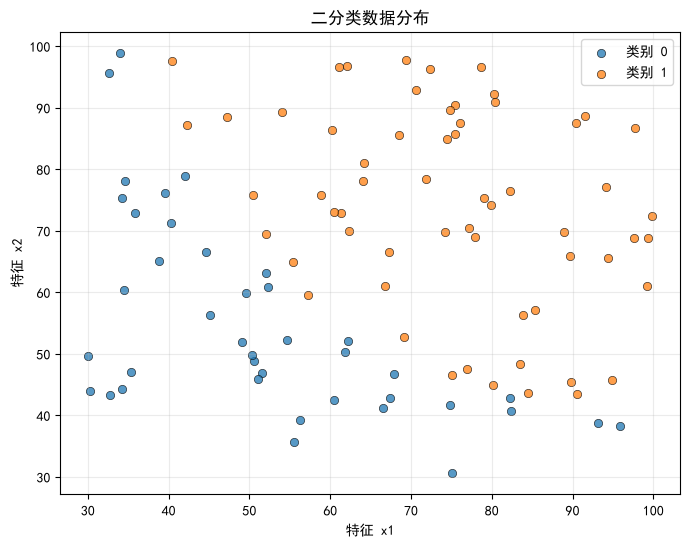

In [ ]:
plt.figure(figsize=(8, 6))
foar label, group in data.groupby("label"):
    plt.scatter(group["x1"],group["x2"],label=f"类别 {label}",alpha=0.75,edgecolors="black",linewidths=0.5)
plt.xlabel("特征 x1") # 添加特征x1的标签
plt.ylabel("特征 x2") # 添加特征x2的标签
plt.title("二分类数据分布") # 添加标题
plt.legend() # 添加图例
plt.grid(alpha=0.25) # 添加网格线
plt.show()


### 思考题

观察上面的散点图：

- 两个类别是否存在明显的分离趋势？
- 是否可以尝试使用一条直线将两个类别分开？
- 如果可以，那么逻辑回归是否适合处理这个问题？

逻辑回归虽然名称中包含“回归”，但它常用于**二分类问题**。模型最终输出一个属于正类的概率，再根据分类阈值完成类别判断。


In [ ]:
X = data[["x1", "x2"]]
y = data["label"]
# 查看X和y的形状
print("X 的形状：", X.shape)
print("y 的形状：", y.shape)


X 的形状： (100, 2)
y 的形状： (100,)


In [14]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=1506,stratify=y)
# 划分数据集后，查看训练集和测试集的样本数
print("训练集样本数：", len(X_train))
print("测试集样本数：", len(X_test))


训练集样本数： 80
测试集样本数： 20


## 八、训练逻辑回归模型

In [15]:
model = LogisticRegression() # 初始化逻辑回归模型
model.fit(X_train, y_train) # 训练模型
print("模型训练完成")
print("模型系数：", model.coef_)
print("模型截距：", model.intercept_)


模型训练完成
模型系数： [[0.1912661  0.20373258]]
模型截距： [-24.20036818]


In [16]:
"""开始预测"""
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]
result = X_test.copy()
result["真实标签"] = y_test.values
result["预测标签"] = y_pred
result["属于类别1的概率"] = y_prob

result.head(10)


,x1,x2,真实标签,预测标签,属于类别1的概率
31,85.404519,57.051984,1,1,0.977201
97,99.315009,68.775409,1,1,0.999850
94,89.845807,45.358284,1,1,0.902476
53,34.524514,60.396342,0,0,0.005005
62,56.253817,39.261473,0,0,0.004312
35,54.635106,52.213886,0,0,0.042580
20,67.372028,42.838438,0,0,0.069993
15,53.971052,89.207350,1,1,0.986572
88,78.635424,96.647427,1,1,0.999973
74,58.840956,75.858448,1,1,0.924753


## 十、模型评价

In [ ]:
accuracy = accuracy_score(y_test, y_pred) # 计算准确率

print(f"测试集准确率：{accuracy:.2%}")

print("\n分类报告：")
print(classification_report(y_test, y_pred))


测试集准确率：95.00%

分类报告：
              precision    recall  f1-score   support

           0       1.00      0.88      0.93         8
           1       0.92      1.00      0.96        12

    accuracy                           0.95        20
   macro avg       0.96      0.94      0.95        20
weighted avg       0.95      0.95      0.95        20



## 十一、混淆矩阵

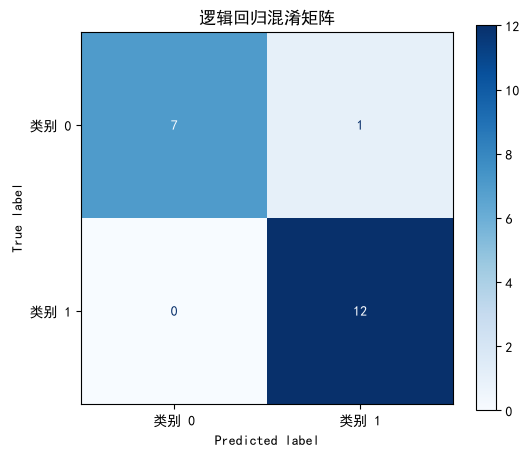

In [19]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["类别 0", "类别 1"]
)

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title("逻辑回归混淆矩阵")
plt.show()


## 十二、绘制逻辑回归决策边界

逻辑回归在本数据集中使用两个特征，因此可以将模型的分类结果直接画在二维平面上。

决策边界对应：

$$
w_1x_1+w_2x_2+b=0
$$

当模型输出的类别概率达到分类阈值时，就会形成分类边界。


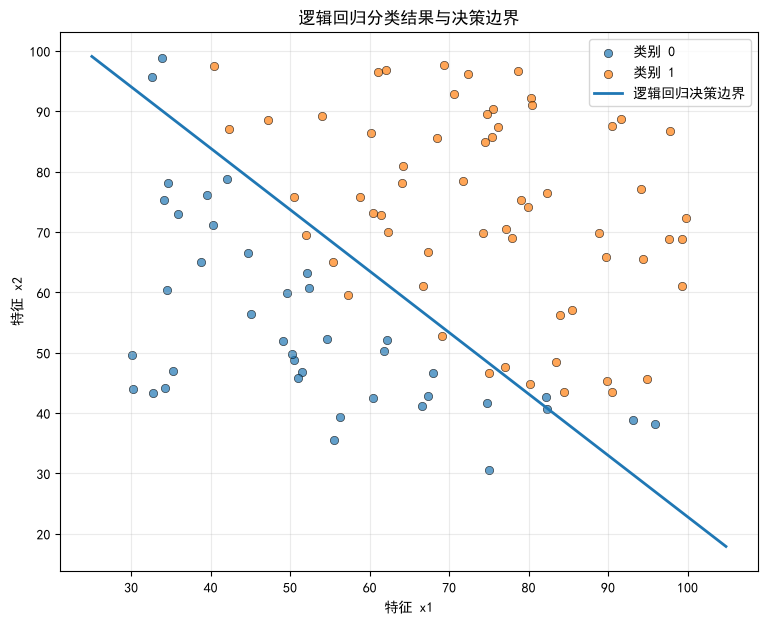

In [ ]:
# 绘制原始样本
plt.figure(figsize=(9, 7))
for label, group in data.groupby("label"):
    plt.scatter(group["x1"], group["x2"], label=f"类别 {label}", alpha=0.7, edgecolors="black",linewidths=0.5)
# 获取模型参数
w1, w2 = model.coef_[0]
b = model.intercept_[0]
# 根据 w1*x1 + w2*x2 + b = 0 计算决策边界
x1_min, x1_max = data["x1"].min() - 5, data["x1"].max() + 5
x1_line = np.linspace(x1_min, x1_max, 200)
if abs(w2) > 1e-12:
    x2_line = -(w1 * x1_line + b) / w2
    plt.plot(
        x1_line,
        x2_line,
        linewidth=2,
        label="逻辑回归决策边界"
    )
plt.xlabel("特征 x1")
plt.ylabel("特征 x2")
plt.title("逻辑回归分类结果与决策边界")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


## 十三、模型预测新样本

下面给出几个新的样本，让模型判断它们属于类别 0 还是类别 1。


In [ ]:
new_samples = pd.DataFrame({
    "x1": [45, 60, 75],
    "x2": [50, 75, 60]
})

new_pred = model.predict(new_samples)
new_prob = model.predict_proba(new_samples)[:, 1]

new_samples["预测类别"] = new_pred
new_samples["类别1概率"] = new_prob

new_samples


'11'

## 十四、课堂练习

### 练习 1：观察数据
修改散点图，尝试增加点大小、透明度或标题信息，使图形更适合教学展示。

### 练习 2：修改测试集比例
将 `test_size=0.2` 修改为 `0.3`，重新训练模型并观察准确率变化。

### 练习 3：修改随机种子
将 `random_state=42` 修改为其他数字，观察训练集和测试集变化后，模型准确率是否发生变化。

### 练习 4：理解预测概率
观察 `predict_proba()` 输出的结果，解释为什么模型不是简单地直接输出 0 或 1。

### 练习 5：决策边界
尝试解释决策边界两侧的样本为什么会被模型预测成不同类别。

### 拓展
尝试改变逻辑回归模型的参数，例如 `C`，比较不同参数下的分类结果和决策边界。


## 十五、课堂小结

本实训完整经历了一个典型的二分类机器学习流程：

**数据读取 → 数据探索 → 数据可视化 → 划分训练集/测试集 → 建立逻辑回归模型 → 模型训练 → 模型预测 → 模型评价 → 决策边界可视化**

核心代码可以概括为：

```python
model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
accuracy_score(y_test, y_pred)
```

通过本案例，可以进一步学习分类算法、Sigmoid 函数、概率预测、分类阈值、混淆矩阵以及决策边界等概念。
